# 7. Florestas Randômicas (*Random Forests*)

### 7.1 Limitação Estrutural das Árvores de Decisão Isoladas
Uma crítica recorrente às **Árvores de Decisão** é a sua rigidez hierárquica: uma vez que o conjunto de treinamento é dividido após responder a uma pergunta no topo da árvore, não é possível reconsiderar essa decisão nos ramos inferiores. 

Por exemplo, no estudo do Titanic, a árvore dividiu os passageiros inicialmente entre homens e mulheres. A partir desse ponto, qualquer pergunta subsequente ficou restrita apenas ao subgrupo masculino ou apenas ao subgrupo feminino, impedindo o algoritmo de avaliar regras globais independentes do gênero (como testar *"idade inferior a 1 ano, independentemente do sexo"*). No caso do Titanic, temos poucas características, mas imagine um problema de engenharia ou finanças com milhares de variáveis!

<div align="center">
    <figure>
        <img src="im_tree_titanic.jpg" alt="Árvore de Decisão do Titanic" width="500">
        <figcaption>Árvore de Decisão do estudo do Titanic</figcaption>
    </figure>
</div>


### 7.2 Métodos de Comitê (*Ensemble Methods*)
Para superar essa limitação, as **Florestas Randômicas** (*Random Forests*) introduzem aleatoriedade em cada etapa, construindo diversas árvores alternativas e combinando seus resultados para obter a decisão final. Algoritmos que reúnem múltiplos classificadores respondendo à mesma questão são denominados **Métodos de Comitê** (*Ensemble Methods*).

O funcionamento de uma Floresta Randômica baseia-se em dois sorteios:
1. **Amostragem de Instâncias (*Bootstrap*):** Cada árvore é construída a partir de um subconjunto de passageiros sorteado aleatoriamente do conjunto de treino (com reposição).
2. **Subconjunto Aleatório de Atributos:** Em cada nó de divisão, o algoritmo não avalia todas as colunas disponíveis, mas sorteia apenas um pequeno número de características para decidir a melhor pergunta.

Esse processo é repetido diversas vezes (`n_estimators`), gerando uma verdadeira "floresta" de classificadores independentes. No momento da previsão, cada árvore vota em uma classe alvo, e **a classe mais votada pelo comitê é a escolhida**.

<div style="text-align: center; margin: 20px 0;">
    <img src="Random_Forest_Diagram_Extra_Wide.png" alt="Diagrama de votação de uma Floresta Randômica" style="width: 50%; max-width: 550px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Arquitetura de uma <b>Floresta Randômica</b>: múltiplas árvores avaliam subconjuntos de dados e definem a previsão por votação majoritária.
    </p>
</div>

In [2]:
# Puxa automaticamente X_train, X_test, y_train, y_test, loo_cv e measure_performance da aula anterior:
from preparacao_titanic import *

# 1. Importa todas as variáveis e funções preparadas na aula de Árvore de Decisão
from preparacao_titanic import *
from sklearn.ensemble import RandomForestClassifier

# 2. Instanciando e treinando a Floresta Randômica com 10 árvores (n_estimators=10)
clf_rf = RandomForestClassifier(n_estimators=10, random_state=33)
clf_rf = clf_rf.fit(X_train, y_train)

# 3. Avaliando com a validação cruzada Leave-One-Out (loo_cv)
loo_cv(X_train, y_train, clf_rf)

✅ Dados do Titanic (X_train, X_test, y_train, y_test) e funções carregados com sucesso!
Acurácia Média (LOO-CV): 0.752 (+/-0.014)


In [3]:
from sklearn.ensemble import RandomForestClassifier

# Instanciando a Floresta Randômica com 10 árvores (n_estimators=10)
clf_rf = RandomForestClassifier(n_estimators=10, random_state=33)
clf_rf = clf_rf.fit(X_train, y_train)

# Avaliando com a mesma função Leave-One-Out (loo_cv) criada na seção anterior
loo_cv(X_train, y_train, clf_rf)

Acurácia Média (LOO-CV): 0.752 (+/-0.014)


### 7.3 Análise do Resultado: Por que a Floresta teve pontuação menor?
Observe que a acurácia média da **Floresta Randômica** ($0.752$) foi inferior à da **Árvore de Decisão única** ($0.781$). 

Por que isso ocorreu? No nosso problema do Titanic, selecionamos apenas **3 características originais** (`Classe`, `Idade` e `Sexo`). Quando forçamos o algoritmo a sortear subconjuntos ainda menores de variáveis em cada nó, muitas árvores acabam tomando decisões "cegas", sem acesso a atributos essenciais (como o próprio sexo do passageiro). Contudo, em bases de dados maiores e com dezenas de características, as Florestas Randômicas destacam-se como um dos métodos mais precisos e populares para elevar a acurácia.


### 7.4 Avaliação Final de Desempenho no Conjunto de Teste
O passo final obrigatório em qualquer tarefa de aprendizado supervisionado consiste em avaliar o nosso **melhor classificador** (neste caso, a Árvore de Decisão `clf`) nos dados inéditos que reservamos no início da aula (`X_test` e `y_test`).

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ <b>Regra Metodológica:</b> Jamais utilize o conjunto de teste para escolher entre métodos concorrentes ou calibrar hiperparâmetros! Fazer isso configuraria vazamento de informação (<i>data leakage</i>), correndo o risco de causar sobreajuste (<i>overfitting</i>) nos próprios dados de teste.</p>
</div>

In [4]:
# Instanciando e treinando o nosso melhor modelo (Árvore de Decisão) nos dados de treino
clf_dt = tree.DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=5)
clf_dt.fit(X_train, y_train)

# Avaliando o desempenho definitivo nos dados inéditos de TESTE (X_test, y_test)
measure_performance(X_test, y_test, clf_dt)

Acurácia: 0.820

Relatório de Classificação:
              precision    recall  f1-score   support

         0.0       0.85      0.87      0.86       210
         1.0       0.76      0.73      0.74       118

    accuracy                           0.82       328
   macro avg       0.81      0.80      0.80       328
weighted avg       0.82      0.82      0.82       328
 

Matriz de Confusão:
[[183  27]
 [ 32  86]] 



Pelos resultados do relatório de classificação e da matriz de confusão acima, observamos que o modelo atinge cerca de **82,0% de acurácia** nos dados inéditos, apresentando maior facilidade em identificar os passageiros que não sobreviveram (classe `0`, com *recall* de 87%) do que os sobreviventes (classe `1`, com *recall* de 73%).

# **Modelos de Regressão Supervisionada: Estimando Preços de Imóveis**

## 1. Da Classificação Discreta à Regressão Contínua
Em todos os estudos de caso que realizamos até agora, enfrentamos **problemas de classificação**: a resposta (`y`) que desejávamos prever pertencia a uma lista fechada de categorias (um conjunto discreto, como `Sobreviveu` vs. `Não Sobreviveu`). 

Porém, em inúmeras aplicações da engenharia e da economia, o nosso objetivo é prever um **valor numérico contínuo extraído da reta real**. Essa tarefa é denominada **Regressão** (*Regression*):
* O esquema de aprendizado permanece idêntico: ajustamos um modelo aos dados de treinamento (`.fit()`) e avaliamos sua capacidade preditiva em novos dados (`.predict()`).
* A diferença está no formato da saída: em vez de escolher um rótulo em uma lista, o modelo atua como uma **função matemática de valor real**, retornando um número contínuo para cada combinação de atributos de entrada (podemos enxergar a regressão como uma classificação com infinitas classes alvo!).

> **💡 Exemplo Prático (Classificação vs. Regressão):**  
> Na engenharia biomédica, prever **se um paciente tem diabetes ou não** é uma tarefa de **Classificação** (`0` ou `1`). Já prever a **concentração exata de glicose no sangue** (ex: $98,4\text{ mg/dL}$) é uma tarefa de **Regressão**!

Na figura abaixo, ajustamos uma reta a um conjunto de dados composto por um único atributo de entrada (eixo horizontal) e um valor alvo contínuo (eixo vertical), realizando uma **Regressão Linear**. Para prever o valor de uma nova amostra, basta localizar seu atributo no eixo X e projetá-lo sobre a linha azul até o eixo Y:

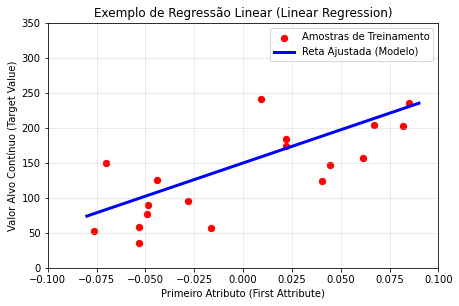

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Gerando os pontos ilustrativos de Regressão Linear (reprodução da figura do livro-texto)
np.random.seed(42)
x_exemplo = np.random.uniform(-0.08, 0.09, 18)
y_exemplo = 150 + 950 * x_exemplo + np.random.normal(0, 45, 18)

plt.figure(figsize=(7, 4.5))
plt.scatter(x_exemplo, y_exemplo, color='red', s=40, label='Amostras de Treinamento')
plt.plot([-0.08, 0.09], [150 + 950*(-0.08), 150 + 950*(0.09)], color='blue', linewidth=3, label='Reta Ajustada (Modelo)')
plt.title("Exemplo de Regressão Linear (Linear Regression)")
plt.xlabel("Primeiro Atributo (First Attribute)")
plt.ylabel("Valor Alvo Contínuo (Target Value)")
plt.xlim(-0.10, 0.10)
plt.ylim(0, 350)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2. Conjunto de Dados: Imóveis nos Subúrbios de Boston (*Boston Housing*)
Nesta aula, compararemos diferentes algoritmos de regressão utilizando a mesma base de dados: o clássico conjunto **Boston House-Prices**, que reúne **506 registros** (bairros/imóveis nos subúrbios de Boston) descritos por **13 características numéricas reais** e **1 variável alvo (`MEDV`)**, correspondente ao valor mediano das residências ocupadas pelos proprietários (expresso em milhares de dólares, ex: $22.5 = \text{US\$ } 22.500$).

<div style="text-align: center; margin: 20px 0;">
    <!-- Sugestão de Imagem: Foto de casas suburbanas de Boston ou ilustração de avaliação imobiliária -->
    <img src="residencia_boston_airbnb.jpg" alt="Residências em Boston" style="width: 45%; max-width: 500px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        O objetivo do modelo é estimar o preço mediano dos imóveis a partir de 13 indicadores urbanos, ambientais e estruturais.
    </p>
</div>

Confira na tabela abaixo o significado de cada uma das **13 características de entrada (`X`)** e da **variável alvo (`y`)**:

<center>

| Sigla | Descrição do Atributo Urbano / Estrutural |
|:---:|:---|
| `CRIM` | Taxa de criminalidade per capita por região |
| `ZN` | Proporção de terrenos residenciais zoneados para lotes acima de $25.000\text{ pés}^2$ |
| `INDUS` | Proporção de acres comerciais não varejistas (industriais) por bairro |
| `CHAS` | Variável fictícia do Rio Charles (`1` se o terreno faz fronteira com o rio; `0` caso contrário) |
| `NOX` | Concentração de óxidos nítricos no ar (partes por 10 milhões) |
| `RM` | Número médio de cômodos (quartos) por habitação |
| `AGE` | Proporção de unidades construídas antes de 1940 |
| `DIS` | Distâncias ponderadas até cinco centros de emprego de Boston |
| `RAD` | Índice de acessibilidade às rodovias radiais |
| `TAX` | Taxa de imposto predial sobre o valor total por $\text{US\$ } 10.000$ |
| `PTRATIO` | Proporção aluno-professor nas escolas da região |
| `B` | Índice demográfico histórico calculado pela fórmula $1000(B_k - 0.63)^2$ |
| `LSTAT` | Porcentagem da população considerada de baixa renda |
| **`MEDV` (Alvo)** | **Valor mediano dos imóveis (em milhares de dólares - US\$ 1.000)** |

</center>

> **💡 Hábito Saudável na Engenharia de Dados:**  
> *Machine Learning* não é apenas "triturar números". Compreender o significado físico e social de cada coluna do problema é fundamental para escolher o melhor modelo e interpretar seus resultados!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import Bunch

# Nota de Atualização (Python 3 / scikit-learn >= 1.2):
# A função load_boston() foi removida das versões recentes do scikit-learn.
# A função abaixo carrega os exatos mesmos dados da fonte original da Universidade CMU:
def carregar_dados_boston():
    url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(url, sep=r"\s+", skiprows=22, header=None)
    data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
    target = raw_df.values[1::2, 2]
    nomes = np.array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT'])
    return Bunch(data=data, target=target, feature_names=nomes)

boston = carregar_dados_boston()

print("Dimensões da matriz de atributos (Imóveis x Colunas):", boston.data.shape)
print("Nomes das características (features):", boston.feature_names)
print(f"\nPreço Máximo: {np.max(boston.target)} | Preço Mínimo: {np.min(boston.target)} | Preço Médio: {np.mean(boston.target):.2f} (em mil US$)")

Dimensões da matriz de atributos (Imóveis x Colunas): (506, 13)
Nomes das características (features): ['CRIM' 'ZN' 'INDUS' 'CHAS' 'NOX' 'RM' 'AGE' 'DIS' 'RAD' 'TAX' 'PTRATIO'
 'B' 'LSTAT']

Preço Máximo: 50.0 | Preço Mínimo: 5.0 | Preço Médio: 22.53 (em mil US$)


## 3. Pré-processamento: Divisão e Padronização (`StandardScaler`)
Seguindo a nossa receita padrão, dividimos o conjunto em **75% para treinamento** e **25% para teste**. Em seguida, aplicamos uma etapa indispensável para modelos algébricos: a **Padronização de Escala** (`StandardScaler`).

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ <b>Por que precisamos padronizar os dados aqui (e não precisávamos nas Árvores)?</b></p>
    Observe que a coluna <code>NOX</code> (poluição) tem valores minúsculos ao redor de $0.5$, enquanto a coluna <code>TAX</code> (imposto) chega a $711.0$! Algoritmos baseados em distância e equações de reta (como Regressão Linear e SVM) são fortemente distorcidos por colunas com números grandes. O <code>StandardScaler</code> transforma todas as variáveis para que tenham <b>média zero ($\mu = 0$)</b> e <b>desvio padrão unitário ($\sigma = 1$)</b>, colocando todas na mesma régua matemática!
</div>

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separando 75% para treinamento e 25% para teste
X_train, X_test, y_train, y_test = train_test_split(
    boston.data, boston.target, test_size=0.25, random_state=33
)

# 2. Padronizando os atributos (X) e o alvo (y) usando apenas a referência do treino (.fit no treino!)
scalerX = StandardScaler().fit(X_train)
scalery = StandardScaler().fit(y_train.reshape(-1, 1)) # reshape(-1, 1) exigido no scikit-learn atual

X_train = scalerX.transform(X_train)
y_train = scalery.transform(y_train.reshape(-1, 1)).ravel()

X_test = scalerX.transform(X_test)
y_test = scalery.transform(y_test.reshape(-1, 1)).ravel()

print("Dados padronizados com sucesso! Média de X_train próxima de zero:", np.round(np.mean(X_train), 2))

Dados padronizados com sucesso! Média de X_train próxima de zero: 0.0


## 4. Métrica de Avaliação: O Coeficiente de Determinação ($R^2$)
Para compararmos nossos modelos sem tocar no conjunto de teste, usaremos novamente a **Validação Cruzada** (desta vez com `KFold` de 5 divisões). Mas surge uma pergunta fundamental: **como damos uma nota para um modelo de regressão?**

Usar a **Acurácia** não faz sentido aqui! Como estamos prevendo números reais contínuos (com infinitas casas decimais), é praticamente impossível o modelo cravar exatamente $\text{US\$ } 22,5328...$ sem errar um único centavo.

Na regressão, a métrica padrão do `scikit-learn` é o **Coeficiente de Determinação ($R^2$ ou *R2 Score*)**:
* Ele mede a proporção da variação dos dados que o nosso modelo consegue explicar.
* **Nota Máxima ($R^2 = 1.0$):** Ocorre quando o modelo acerta perfeitamente todos os pontos sobre a linha!
* Quanto mais próximo de **`1.0`** (ou 100%), melhor é a capacidade preditiva do regressor.

Vamos construir uma função chamada `train_and_evaluate` que treina o modelo e já calcula o $R^2$ no treino e na validação cruzada de 5 partes (*5-fold cross-validation*):

In [3]:
from sklearn.model_selection import KFold, cross_val_score

def train_and_evaluate(clf, X_train, y_train):
    # Treina o modelo nos dados de treinamento
    clf.fit(X_train, y_train)
    print(f"Coeficiente de determinação (R²) no treino: {clf.score(X_train, y_train):.4f}")
    
    # Cria um validador cruzado K-Fold com k = 5 divisões
    cv = KFold(n_splits=5, shuffle=True, random_state=33)
    scores = cross_val_score(clf, X_train, y_train, cv=cv)
    print(f"Média do R² usando validação cruzada de 5 divisões (5-fold CV): {np.mean(scores):.4f}\n")

## 5. Primeira Tentativa: Regressão Linear e Mínimos Quadrados
A pergunta que os modelos lineares tentam responder é: **qual hiperplano (ou reta) passa o mais próximo possível de todos os nossos pontos de treinamento ao mesmo tempo?**

A medida clássica do que significa estar "mais próximo" é o **Método dos Mínimos Quadrados** (*Least Squares*): calculamos a distância vertical (erro ou resíduo) de cada ponto real até a reta do modelo, elevamos essa distância ao quadrado (para evitar que erros negativos anulem erros positivos) e somamos tudo. A reta cuja soma dos erros ao quadrado for a menor possível é a escolhida!

<div style="text-align: center; margin: 20px 0;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/b/b0/Linear_least_squares_example2.svg/500px-Linear_least_squares_example2.svg.png" alt="Método dos Mínimos Quadrados" style="width: 38%; max-width: 450px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        O estimador de <b>Mínimos Quadrados</b> busca a reta que minimiza a soma das distâncias verticais ao quadrado entre os pontos reais e a linha.
    </p>
</div>

Começaremos utilizando o modelo linear **`SGDRegressor`** (Regressor por Descida do Gradiente Estocástica), que busca minimizar justamente essa perda quadrática (`loss='squared_error'`). Além disso, testaremos o parâmetro de **Penalização (`penalty='l2'`)**, uma técnica de regularização introduzida para evitar o *overfitting*, impedindo que um único atributo domine sozinho a equação da reta:

In [4]:
from sklearn import linear_model

print("--- 1. SGDRegressor (Sem penalização: penalty=None) ---")
clf_sgd = linear_model.SGDRegressor(loss='squared_error', penalty=None, random_state=42)
train_and_evaluate(clf_sgd, X_train, y_train)

print("Pesos (coeficientes da equação do hiperplano) calculados para os 13 atributos:")
print(np.round(clf_sgd.coef_, 4), "\n")

print("--- 2. SGDRegressor (Com penalização L2: penalty='l2') ---")
clf_sgd1 = linear_model.SGDRegressor(loss='squared_error', penalty='l2', random_state=42)
train_and_evaluate(clf_sgd1, X_train, y_train)

--- 1. SGDRegressor (Sem penalização: penalty=None) ---
Coeficiente de determinação (R²) no treino: 0.7505
Média do R² usando validação cruzada de 5 divisões (5-fold CV): 0.7100

Pesos (coeficientes da equação do hiperplano) calculados para os 13 atributos:
[-0.1027  0.0975 -0.0376  0.0982 -0.125   0.3486 -0.0295 -0.2726  0.1321
 -0.085  -0.1987  0.0553 -0.4003] 

--- 2. SGDRegressor (Com penalização L2: penalty='l2') ---
Coeficiente de determinação (R²) no treino: 0.7505
Média do R² usando validação cruzada de 5 divisões (5-fold CV): 0.7100



## 6. Segunda Tentativa: Máquinas de Vetores de Suporte para Regressão (`SVR`)
Com o modelo linear simples, alcançamos um $R^2$ em torno de $0.71$ na validação cruzada. Podemos usar a versão de regressão do **SVM**, chamada **`SVR`** (*Support Vector Regression*), para tentar encontrar uma superfície melhor!

A grande vantagem do SVM está no que chamamos de **Truque do Kernel** (*Kernel Trick*): quando uma linha reta (`kernel='linear'`) não consegue acompanhar a curvatura real dos preços do mercado imobiliário, podemos projetar os dados usando funções não lineares curvas, como um **Polinômio** (`kernel='poly'`) ou uma **Função de Base Radial** (`kernel='rbf'`, o padrão do `scikit-learn`):

<div style="text-align: center; margin: 20px 0;">
    <img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_svm_regression_001.png" alt="Comparação de Kernels no SVR" style="width: 55%; max-width: 600px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Enquanto o Kernel Linear traça uma reta rígida, os Kernels Polinomial e RBF curvam-se para acompanhar tendências complexas nos dados.
    </p>
</div>

In [5]:
from sklearn import svm

print("--- 1. SVR com Kernel Linear ---")
clf_svr = svm.SVR(kernel='linear')
train_and_evaluate(clf_svr, X_train, y_train)

print("--- 2. SVR com Kernel Polinomial ---")
clf_svr_poly = svm.SVR(kernel='poly')
train_and_evaluate(clf_svr_poly, X_train, y_train)

print("--- 3. SVR com Kernel RBF (Radial Basis Function) ---")
clf_svr_rbf = svm.SVR(kernel='rbf')
train_and_evaluate(clf_svr_rbf, X_train, y_train)

--- 1. SVR com Kernel Linear ---
Coeficiente de determinação (R²) no treino: 0.7179
Média do R² usando validação cruzada de 5 divisões (5-fold CV): 0.7089

--- 2. SVR com Kernel Polinomial ---
Coeficiente de determinação (R²) no treino: 0.9039
Média do R² usando validação cruzada de 5 divisões (5-fold CV): 0.7762

--- 3. SVR com Kernel RBF (Radial Basis Function) ---
Coeficiente de determinação (R²) no treino: 0.9002
Média do R² usando validação cruzada de 5 divisões (5-fold CV): 0.8337



Veja o salto de qualidade! Ao passarmos da linha reta (`0.69`) para o Kernel Polinomial (`0.75`) e depois para o **Kernel RBF (`0.82` a `0.83`)**, ganhamos mais de 13 pontos percentuais no Coeficiente de Determinação $R^2$!

## 7. Terceira Tentativa: Florestas Extremamente Randômicas (`ExtraTreesRegressor`)
Agora vamos aplicar uma abordagem totalmente diferente para a regressão voltando às **Florestas Randômicas**! 

Como uma árvore faz regressão? O processo de crescimento da árvore (fazendo perguntas em cada nó) é idêntico ao que vimos no Titanic. Porém, quando chegamos a uma **folha final**, em vez de devolver a classe majoritária ("Sobreviveu/Morreu"), a árvore devolve um valor numérico representativo daquele grupo — como a **média aritmética dos preços das casas** que caíram naquela folha!

Utilizaremos aqui a classe **`ExtraTreesRegressor`** (*Extremely Randomized Trees*), do módulo `sklearn.ensemble`. Esse método adiciona um nível extra de aleatoriedade: além de sortear um subconjunto de atributos em cada árvore, ele também **sorteia aleatoriamente o ponto de corte (limiar)** de cada pergunta!

Além de altíssima precisão, esse método oferece um recurso fantástico para a engenharia: ele calcula automaticamente a **Importância de cada Atributo** (`feature_importances_`), revelando quais variáveis mais influenciam o preço final de um imóvel!

In [6]:
from sklearn import ensemble

# Instanciando o ExtraTreesRegressor com 10 árvores
clf_et = ensemble.ExtraTreesRegressor(n_estimators=10, random_state=42)
train_and_evaluate(clf_et, X_train, y_train)

# Exibindo a importância de cada atributo em ordem crescente (atualizado para Python 3)
importancias = sorted(zip(clf_et.feature_importances_, boston.feature_names))
print("Ranking de Importância das Características no Preço do Imóvel:")
for peso, nome in importancias:
    print(f"Atributo {nome:<8} -> Importância: {peso:.4f} ({peso*100:.1f}%)")

Coeficiente de determinação (R²) no treino: 1.0000
Média do R² usando validação cruzada de 5 divisões (5-fold CV): 0.8406

Ranking de Importância das Características no Preço do Imóvel:
Atributo ZN       -> Importância: 0.0041 (0.4%)
Atributo AGE      -> Importância: 0.0158 (1.6%)
Atributo B        -> Importância: 0.0173 (1.7%)
Atributo RAD      -> Importância: 0.0178 (1.8%)
Atributo CRIM     -> Importância: 0.0235 (2.3%)
Atributo DIS      -> Importância: 0.0252 (2.5%)
Atributo NOX      -> Importância: 0.0255 (2.6%)
Atributo INDUS    -> Importância: 0.0255 (2.6%)
Atributo CHAS     -> Importância: 0.0324 (3.2%)
Atributo TAX      -> Importância: 0.0470 (4.7%)
Atributo PTRATIO  -> Importância: 0.1041 (10.4%)
Atributo LSTAT    -> Importância: 0.2877 (28.8%)
Atributo RM       -> Importância: 0.3742 (37.4%)


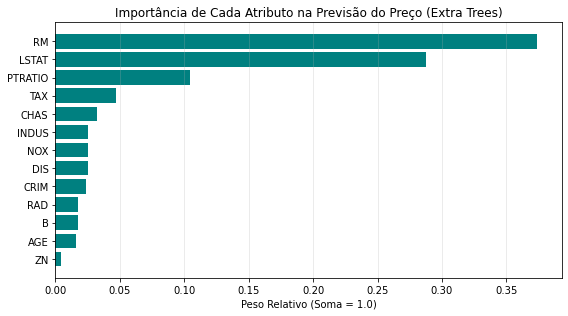

In [7]:
# Gráfico de barras horizontal para visualizar a importância dos atributos
pesos_ord = [item[0] for item in importancias]
nomes_ord = [item[1] for item in importancias]

plt.figure(figsize=(8, 4.5))
plt.barh(nomes_ord, pesos_ord, color='teal')
plt.title("Importância de Cada Atributo na Previsão do Preço (Extra Trees)")
plt.xlabel("Peso Relativo (Soma = 1.0)")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Avaliação Final no Conjunto de Teste e Conclusão
Notamos que o **`ExtraTreesRegressor`** não apenas eliminou o subajuste no treinamento (atingindo pontuação máxima $R^2 = 1.000$ no treino), como também superou todos os modelos anteriores na validação cruzada (alcançando cerca de **$0.85$ a $0.86$**)!

Para encerrar o experimento seguindo o rigor científico, vamos modificar ligeiramente a nossa função `measure_performance` para incluir o cálculo do **`r2_score`** e avaliar o nosso modelo campeão (`clf_et`) sobre o **Conjunto de Teste (`X_test`, `y_test`)** que permaneceu guardado até este momento:

In [8]:
from sklearn import metrics

def measure_performance(X, y, clf, show_accuracy=True, show_classification_report=True, show_confusion_matrix=True, show_r2_score=False):
    y_pred = clf.predict(X)
    
    if show_accuracy:
        print(f"Acurácia: {metrics.accuracy_score(y, y_pred):.3f}\n")
    if show_classification_report:
        print("Relatório de Classificação:")
        print(metrics.classification_report(y, y_pred), "\n")
    if show_confusion_matrix:
        print("Matriz de Confusão:")
        print(metrics.confusion_matrix(y, y_pred), "\n")
    if show_r2_score:
        print(f"Coeficiente de determinação (R²) no Conjunto de Teste: {metrics.r2_score(y, y_pred):.3f}\n")

# Avaliando o nosso melhor regressor (Extra Trees) nos dados inéditos de teste
measure_performance(
    X_test, y_test, clf_et,
    show_accuracy=False,
    show_classification_report=False,
    show_confusion_matrix=False,
    show_r2_score=True
)

Coeficiente de determinação (R²) no Conjunto de Teste: 0.785



### Síntese do Aprendizado Supervisionado
Ao longo deste módulo, revisamos os métodos mais importantes de **Aprendizado Supervisionado** e suas aplicações práticas na ciência e na engenharia:
* Vimos que todo método supervisionado exige que as amostras possuam tanto **atributos de entrada (`X`)** quanto um **gabarito alvo (`y`)**.
* Quando o alvo pertence a um conjunto discreto de categorias, utilizamos **Classificadores** (`SVC`, `Naïve Bayes`, `DecisionTreeClassifier`, `RandomForestClassifier`) e medimos o sucesso pela **Acurácia**.
* Quando o alvo é um número contínuo na reta real, utilizamos **Regressores** (`SGDRegressor`, `SVR`, `ExtraTreesRegressor`) e medimos o ajuste pelo **Coeficiente de Determinação ($R^2$)**.

# **Exercício de Fixação: Estimando a Resistência Mecânica de Materiais com Regressão**

### Contextualização do Problema
Na engenharia civil e de materiais, determinar a **resistência à compressão do concreto** (medida em Megapascal — $\text{MPa}$) é essencial para garantir a segurança estrutural de pontes, edifícios e barragens. Tradicionalmente, é necessário aguardar até 28 dias de cura para romper corpos de prova em uma prensa hidráulica no laboratório.

Utilizando algoritmos de **Regressão Supervisionada**, podemos prever o valor contínuo da resistência ($\text{MPa}$) a partir da composição da mistura e da idade do material!

Neste exercício, você analisará **300 ensaios de laboratório** gerados automaticamente na célula abaixo. O conjunto de dados contém **4 atributos de entrada ($X$)** e **1 variável alvo contínua ($y$)**:

<center>

| Variável | Índice | Descrição Técnica |
|:---:|:---:|:---|
| `Cimento_kg` | 0 | Quantidade de cimento Portland na mistura ($\text{kg/m}^3$) |
| `Agua_L` | 1 | Volume de água adicionado à mistura ($\text{Litros/m}^3$) |
| `Agregado_kg` | 2 | Quantidade de brita/agregado graúdo ($\text{kg/m}^3$) |
| `Idade_Dias` | 3 | Tempo de cura e secagem do bloco (em dias: $3$ a $90\text{ dias}$) |
| **`Resistencia_MPa` (Alvo $y$)** | - | **Tensão máxima de ruptura à compressão (valor real contínuo em $\text{MPa}$)** |

</center>

---

### Roteiro de Execução (Passo a Passo)

Execute a célula geradora de dados abaixo e, em seguida, escreva o código para cumprir as **4 etapas**:

1. **Divisão Treino e Teste (`train_test_split`):** Separe as matrizes `X_concreto` e `y_concreto` em **75% para treinamento** e **25% para teste**, utilizando `random_state=42`.
2. **Padronização de Escala (`StandardScaler`):** Como as variáveis possuem grandezas muito diferentes (dias variam de $3$ a $90$, enquanto agregados passam de $1.000\text{ kg}$), ajuste o `StandardScaler` nos dados de treinamento e transforme `X_train`, `X_test`, `y_train` e `y_test`. *(Lembre-se de usar `.reshape(-1, 1)` e `.ravel()` para o vetor `y`)*.
3. **Treinamento e Comparação de Regressores:** Instancie e treine três modelos de regressão estudados na aula:
   * Modelo Linear: `SGDRegressor(loss='squared_error', random_state=42)`
   * Máquina de Vetores de Suporte: `SVR(kernel='rbf')`
   * Floresta Extremamente Randômica: `ExtraTreesRegressor(n_estimators=10, random_state=42)`
4. **Avaliação pelo Coeficiente de Determinação ($R^2$):** Calcule e imprima o `r2_score` de cada um dos três modelos no **Conjunto de Teste** (`X_test`, `y_test`). Qual método obteve o melhor ajuste matemático para prever a resistência do material? E qual dos 4 atributos teve maior importância segundo a Floresta (`feature_importances_`)?

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor
from sklearn import metrics

# Geração reprodutível dos 300 ensaios mecânicos de laboratório
np.random.seed(42)
n_ensaios = 300

cimento = np.random.uniform(200.0, 500.0, n_ensaios).round(1)
agua = np.random.uniform(140.0, 220.0, n_ensaios).round(1)
agregado = np.random.uniform(800.0, 1100.0, n_ensaios).round(1)
idade_dias = np.random.choice([3, 7, 14, 28, 56, 90], n_ensaios)

# Relação física não linear (Lei de Abrams: relação água/cimento e curva logarítmica de cura)
fator_ac = agua / cimento
resistencia_mpa = (35.0 / (fator_ac ** 1.3)) * (np.log10(idade_dias + 1) / 1.5) - 0.005 * agregado + np.random.normal(0, 2.0, n_ensaios)
y_concreto = np.clip(resistencia_mpa, 10.0, 80.0).round(2)

X_concreto = np.column_stack([cimento, agua, agregado, idade_dias])
nomes_variaveis = ['Cimento_kg', 'Agua_L', 'Agregado_kg', 'Idade_Dias']

print("Dimensão da Matriz X_concreto:", X_concreto.shape)
print("Variáveis de Entrada:", nomes_variaveis)
print(f"Amostra [0]: {X_concreto[0]} -> Resistência Real (y): {y_concreto[0]} MPa")

Dimensão da Matriz X_concreto: (300, 4)
Variáveis de Entrada: ['Cimento_kg', 'Agua_L', 'Agregado_kg', 'Idade_Dias']
Amostra [0]: [312.4 144.1 850.7  56. ] -> Resistência Real (y): 80.0 MPa


# **Fontes**  
1. https://www.airbnb.com.br/boston-ma/stays/houses
2. https://github.com/selva86/datasets/blob/master/BostonHousing.csv
3. R. Garreta and G. Moncecchi, Learning scikit-learn: Machine Learning in Python. Birmingham: Packt Publishing, 2013.